# Étape 3 — Détection : « où sont les avions ? »

**Objectif :** entraîner un modèle qui trouve **tous les avions** d'une image complète
et dessine une boîte autour de chacun. C'est le premier étage de notre système.

| Choix | Pourquoi |
|---|---|
| **YOLO11n** (Ultralytics) | un détecteur rapide : il trouve tous les objets en un seul passage sur l'image (*You Only Look Once*). La version « nano » n'a que 2,6 millions de paramètres |
| **pré-entraîné sur COCO** | il a déjà appris à voir des objets (dont des avions) sur 118 000 photos : c'est du **transfer learning** |
| **une seule classe, « avion »** | le détecteur dit seulement *où* sont les avions ; le *type* (A1 à A20) est le travail du classifieur, à l'étape 4 |
| images en **800 × 800 px** | leur taille d'origine : réduire les images ferait disparaître les petits avions (étape 1) |

**Important :** l'entraînement a été fait sur **Google Colab** (carte graphique), car
la carte graphique du PC provoquait des écrans bleus. La cellule d'entraînement est
donc désactivée par défaut : ce notebook charge le modèle entraîné et le
**re-mesure sur la validation**, sur le processeur.

Pré-requis : l'étape 2 (le dossier `data/yolo/`).

## Pour relancer sur Google Colab (facultatif)

En local, la cellule suivante ne fait rien. Sur Colab, avec une carte graphique, c'est
ainsi que nos modèles ont été entraînés :
1. copier le dossier du projet dans le Drive, sous `Mon Drive/projet_avions` ;
2. ouvrir le notebook dans Colab (Exécution > Modifier le type d'exécution > GPU) ;
3. lancer d'abord l'étape 2, qui prépare `data/yolo/` et `data/crops/` sur Colab ;
4. dans les étapes 3 et 4, exécuter la cellule ci-dessous, puis mettre `ENTRAINER = True`.

In [1]:
import os
import subprocess
import sys

SUR_COLAB = "google.colab" in sys.modules
if SUR_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    os.chdir("/content/drive/MyDrive/projet_avions/etapes")
    # Ultralytics (YOLO), dans la même version que sur le PC
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "ultralytics==8.4.189"], check=True
    )
else:
    print("Exécution locale : rien à faire.")

Exécution locale : rien à faire.


## 0. Préparation

In [2]:
import shutil
import tempfile
import xml.etree.ElementTree as ET
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import pandas as pd
from ultralytics import YOLO

# Le notebook se lance depuis le dossier etapes/ : la racine du projet est le dossier parent
RACINE = Path.cwd().parent
RAW_IMAGES_DIR = RACINE / "data" / "raw" / "images"  # 1331 images satellites .jpg
RAW_ANNOTATIONS_DIR = RACINE / "data" / "raw" / "annotations"  # 1331 fichiers .xml (Pascal VOC)
YOLO_DATASET_YAML = RACINE / "data" / "yolo" / "dataset.yaml"  # écrit à l'étape 2
MODELS_DIR = RACINE / "models"  # poids finaux de nos modèles
RUNS_DIR = RACINE / "runs"  # sorties des entraînements (courbes, métriques)
assert YOLO_DATASET_YAML.exists(), "Lancer d'abord l'étape 2 (préparation des données)"
assert RAW_IMAGES_DIR.exists(), f"Dataset du prof introuvable : {RAW_IMAGES_DIR}"

## 1. Les réglages de l'entraînement

Chaque réglage est un paramètre de `model.train()` d'Ultralytics.
La **data augmentation** suit l'analyse des données : vu du ciel, il n'y a ni
« haut » ni « bas », donc on retourne les images au hasard.

In [3]:
CONFIG = {
    "name": "detecteur_1classe",  # nom du dossier dans runs/ et du fichier dans models/
    "model": "yolo11n.pt",  # YOLO11 « nano » pré-entraîné sur COCO : transfer learning
    "single_cls": True,  # A1…A20 fusionnées en une seule classe « avion »
    # Entraînement
    "imgsz": 800,  # résolution d'origine des images : on ne les réduit pas
    "epochs": 80,  # nombre maximal de passages sur tout le jeu d'entraînement
    "patience": 15,  # early stopping : arrêt si la validation stagne 15 epochs
    "batch": 16,  # images traitées en même temps
    "workers": 4,  # processus qui chargent les images en parallèle
    "seed": 0,  # graine fixe : entraînement reproductible
    # Data augmentation
    "fliplr": 0.5,  # retournement gauche-droite, une image sur deux
    "flipud": 0.5,  # retournement haut-bas, une image sur deux
    "degrees": 0,  # pas de rotation quelconque : elle agrandirait les boîtes
    "close_mosaic": 10,  # 10 dernières epochs sans « mosaïque » (4 images collées)
}

## 2. L'entraînement

Pendant l'entraînement, YOLO passe plusieurs fois sur les 1 070 images de train
(une **epoch** = un passage). Après chaque epoch, il se mesure sur la **validation**
et garde les poids de la meilleure epoch (`best.pt`). Il s'arrête tout seul si la
validation ne progresse plus pendant 15 epochs : c'est l'**early stopping**, contre
le sur-apprentissage.

Mettre `ENTRAINER = True` **seulement sur Colab** (environ 30 minutes avec une carte
graphique). Jamais sur ce PC.

In [4]:
ENTRAINER = False

if ENTRAINER:
    model = YOLO(CONFIG["model"])  # poids COCO, téléchargés automatiquement la première fois
    reglages = {key: value for key, value in CONFIG.items() if key != "model"}
    # exist_ok : relancer avec le même nom remplace le dossier au lieu d'en créer un autre
    model.train(data=str(YOLO_DATASET_YAML), project=str(RUNS_DIR), exist_ok=True, **reglages)
    # On garde une copie des meilleurs poids dans models/, sous un nom simple
    best_weights = Path(model.trainer.save_dir) / "weights" / "best.pt"
    shutil.copy2(best_weights, MODELS_DIR / f"{CONFIG['name']}.pt")
else:
    print(
        "Entraînement déjà fait sur Colab. Modèle utilisé :",
        (MODELS_DIR / "detecteur_1classe.pt").relative_to(RACINE),
    )

Entraînement déjà fait sur Colab. Modèle utilisé : models\detecteur_1classe.pt


## 3. Les courbes d'apprentissage

Ultralytics enregistre les scores de chaque epoch dans `runs/detecteur_1classe/results.csv`.
On les relit pour voir comment l'entraînement s'est passé sur Colab :

| Mesure | Signification |
|---|---|
| **box loss** | l'erreur sur la position des boîtes : elle doit baisser |
| **précision** | parmi les boîtes proposées, la part qui est vraiment un avion |
| **rappel** | parmi les vrais avions, la part qui a été trouvée |
| **mAP50** | la qualité globale : l'aire sous la courbe précision-rappel, une boîte comptant comme juste si elle recouvre l'avion à au moins 50 % (IoU ≥ 0,5) |
| **mAP50-95** | la même chose, mais en exigeant des boîtes de plus en plus précises (IoU de 0,5 à 0,95). C'est le critère qui choisit la meilleure epoch |

67 epochs (arrêt anticipé), meilleure epoch : 52


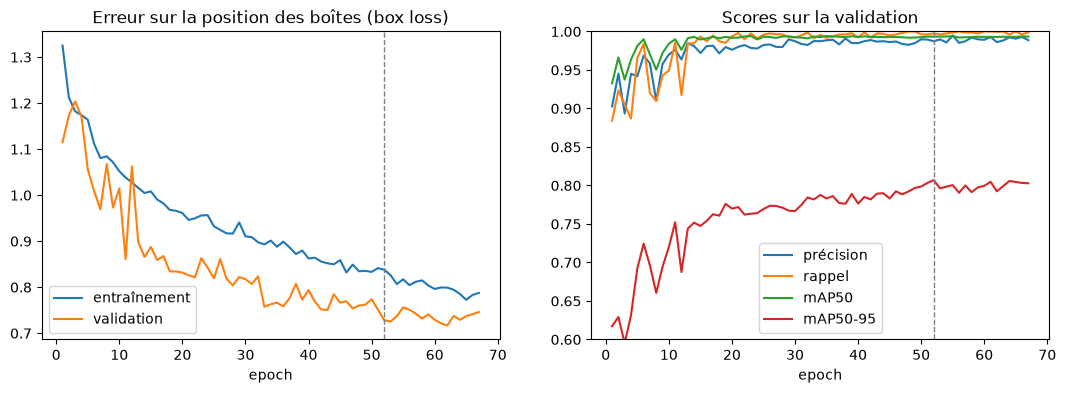

In [5]:
history = pd.read_csv(RUNS_DIR / "detecteur_1classe" / "results.csv")
best = history.loc[history["metrics/mAP50-95(B)"].idxmax()]
print(f"{len(history)} epochs (arrêt anticipé), meilleure epoch : {int(best['epoch'])}")

fig, (ax_loss, ax_score) = plt.subplots(1, 2, figsize=(13, 4))
ax_loss.plot(history["epoch"], history["train/box_loss"], label="entraînement")
ax_loss.plot(history["epoch"], history["val/box_loss"], label="validation")
ax_loss.set_title("Erreur sur la position des boîtes (box loss)")
for column, label in [
    ("metrics/precision(B)", "précision"),
    ("metrics/recall(B)", "rappel"),
    ("metrics/mAP50(B)", "mAP50"),
    ("metrics/mAP50-95(B)", "mAP50-95"),
]:
    ax_score.plot(history["epoch"], history[column], label=label)
ax_score.set_title("Scores sur la validation")
ax_score.set_ylim(0.6, 1.0)
for ax in (ax_loss, ax_score):
    ax.axvline(best["epoch"], color="gray", linestyle="--", linewidth=1)
    ax.set_xlabel("epoch")
    ax.legend()
plt.show()

## 4. Le détecteur sur la validation

On recharge le modèle final et on le mesure à nouveau sur les images de
**validation**, jamais vues pendant l'apprentissage. Tout tourne sur le processeur,
en une minute environ.

L'avertissement « Skipping labels of classes… » est sans conséquence : avec
`single_cls=True`, les 787 avions sont tous comptés comme « avion » (colonne
*Instances*).

L'avertissement « Skipping labels of classes… » est sans conséquence : avec
`single_cls=True`, les 787 avions sont tous comptés comme « avion » (colonne
*Instances*).

In [6]:
detector = YOLO(str(MODELS_DIR / "detecteur_1classe.pt"))
metrics = detector.val(
    data=str(YOLO_DATASET_YAML),
    split="val",
    imgsz=800,
    batch=8,
    single_cls=True,
    device="cpu",
    plots=False,
    project=tempfile.mkdtemp(),  # dossier temporaire : rien n'est écrit dans le projet
    verbose=False,
)
pd.Series(
    {
        "précision": metrics.box.mp,
        "rappel": metrics.box.mr,
        "mAP50": metrics.box.map50,
        "mAP50-95": metrics.box.map,
    },
    name="validation",
).round(3).to_frame()

Ultralytics 8.4.189  Python-3.11.17 torch-2.14.1+cu132 CPU (12th Gen Intel Core i7-12700H)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 945.9±501.0 MB/s, size: 306.2 KB)
val: Scanning projet_ia\data\yolo\labels\val... 130 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 130/130 1.3Kit/s 0.1s
val: New cache created: projet_ia\data\yolo\labels\val.cache
WARNING Skipping labels of classes the model (nc=1) cannot predict.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 17/17 1.3it/s 13.5s
                   all        130        787      0.987      0.997      0.993      0.809
Speed: 4.0ms preprocess, 86.1ms inference, 0.0ms loss, 0.6ms postprocess per image


,validation
précision,0.987
rappel,0.997
mAP50,0.993
mAP50-95,0.809


## 5. Un exemple

L'image 1453 fait partie de la validation. À gauche, les vraies boîtes du fichier XML ;
à droite, celles trouvées par le détecteur, avec sa **confiance** (de 0 à 1).
On ne garde que les boîtes d'une confiance d'au moins 0,5.

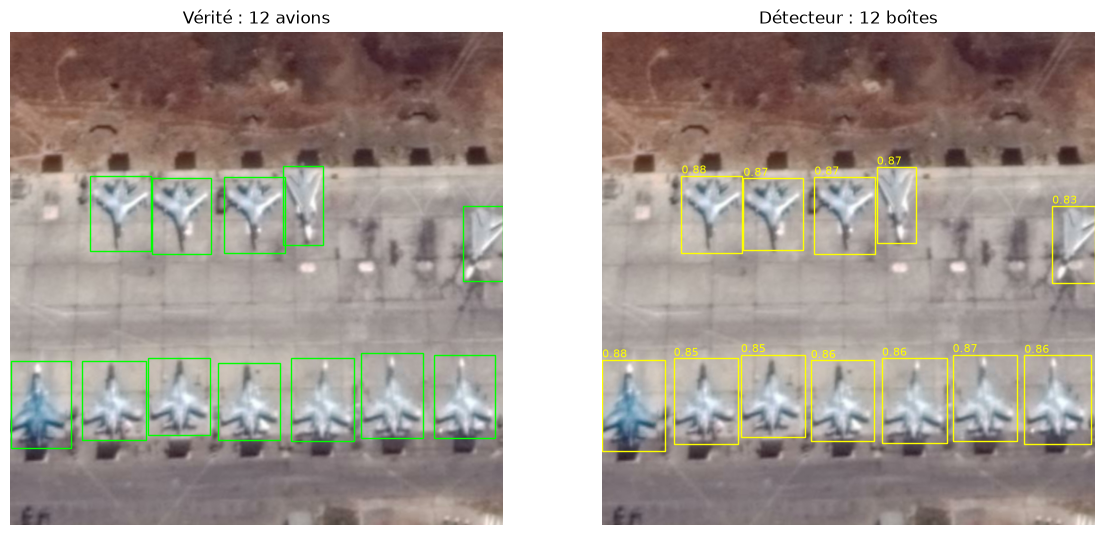

In [7]:
IMAGE_ID = "1453"
image = cv2.imread(str(RAW_IMAGES_DIR / f"{IMAGE_ID}.jpg"))
result = detector.predict(image, imgsz=800, conf=0.5, iou=0.7, device="cpu", verbose=False)[0]
boxes, scores = result.boxes.xyxy.numpy(), result.boxes.conf.numpy()

# Les vraies boîtes, lues dans le fichier XML de l'image
racine_xml = ET.parse(RAW_ANNOTATIONS_DIR / f"{IMAGE_ID}.xml").getroot()
vraies_boites = [
    [int(obj.find("bndbox").findtext(tag)) for tag in ("xmin", "ymin", "xmax", "ymax")]
    for obj in racine_xml.iter("object")
]

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
titres = [f"Vérité : {len(vraies_boites)} avions", f"Détecteur : {len(boxes)} boîtes"]
for ax, titre in zip(axes, titres, strict=True):
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax.set_title(titre)
    ax.axis("off")
for xmin, ymin, xmax, ymax in vraies_boites:
    axes[0].add_patch(
        plt.Rectangle((xmin, ymin), xmax - xmin, ymax - ymin, fill=False, color="lime")
    )
for (xmin, ymin, xmax, ymax), score in zip(boxes, scores, strict=True):
    axes[1].add_patch(
        plt.Rectangle((xmin, ymin), xmax - xmin, ymax - ymin, fill=False, color="yellow")
    )
    axes[1].text(xmin, ymin - 4, f"{score:.2f}", color="yellow", fontsize=8)
plt.show()

## 6. Ce qu'il faut retenir

- **Transfer learning** : on part d'un YOLO11n qui sait déjà voir des objets (COCO),
  et on le spécialise sur nos avions.
- **Une seule classe** : le détecteur ne s'occupe que de *où*, ce qui lui permet
  d'être excellent (rappel proche de 1 : il ne rate presque aucun avion).
- **Early stopping** : l'entraînement s'arrête quand la validation ne progresse plus,
  et on garde la meilleure epoch.
- **Data augmentation** : des retournements, mais pas de rotation quelconque, qui
  agrandirait les boîtes.

Suite : **étape 4, la classification**.